In [41]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [13]:
PERFORMANCE_EXPORT_FOLDER = "performance"
CONFIG_FILE = "config.json"
PERFORMANCE_FILE = "performance.csv"
DETAIL_PERFORMANCE_FILE = "detail_performance.csv"

In [14]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [15]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera Wired',
  'ip_address': 

In [16]:
folders = [PERFORMANCE_EXPORT_FOLDER + "/" + file.name for file in Path(PERFORMANCE_EXPORT_FOLDER).iterdir()]
folders

['performance/incoming_total_bytes_incoming_idle_time__no_dropping__nonIot-vs-iot',
 'performance/incoming_packet_count_incoming_idle_time__drop_router__nonIot-vs-iot-vs-iotHealthCare',
 'performance/outgoing_packet_count_outgoing_total_bytes_outgoing_idle_time__drop_router_and_camera__nonIot-vs-iot',
 'performance/incoming_packet_count_incoming_total_bytes_incoming_idle_time_outgoing_packet_count_outgoing_total_bytes_outgoing_idle_time__drop_router_and_hub__nonIot-vs-iot-vs-iotHealthCare',
 'performance/outgoing_packet_count_outgoing_idle_time__drop_router__nonIot-vs-iot-vs-iotCamera',
 'performance/incoming_packet_count_incoming_total_bytes_incoming_idle_time_outgoing_packet_count_outgoing_total_bytes_outgoing_idle_time__no_dropping__nonIot-vs-iot-vs-iotHealthCare',
 'performance/incoming_packet_count_incoming_total_bytes_incoming_idle_time_outgoing_packet_count_outgoing_total_bytes_outgoing_idle_time__no_dropping__nonIot-vs-iot',
 'performance/incoming_packet_count_incoming_total_by

In [18]:
# Load all performance
all_perfs = {}
for folder in folders:
    key = folder.split("/")[-1]
    if key in all_perfs:
        raise ValueError("Duplicated config")
    
    config = {}
    config_file = f"{folder}/{CONFIG_FILE}"
    metric_file = f"{folder}/{PERFORMANCE_FILE}"
    detail_file = f"{folder}/{DETAIL_PERFORMANCE_FILE}"
    with open(config_file, "r") as f:
        config = json.load(f)
    metric_df = pd.read_csv(metric_file)
    detail_file = pd.read_csv(detail_file)
    config["performance"] = metric_df
    config["detail_performance"] = detail_file
    all_perfs[key] = config

In [21]:
all_perfs

{'incoming_total_bytes_incoming_idle_time__no_dropping__nonIot-vs-iot': {'feature_combination': ['incoming_total_bytes',
   'incoming_idle_time'],
  'dropping_strategy': 'no_dropping',
  'labeling_strategy': 'nonIot-vs-iot',
  'class_labels': [0, 1],
  'feature_set': 'incoming_data',
  'average_across_all_windows': 0.9325714285714287,
  'performance':      accuracy  device_count  correct_count  misclassified_count  \
  0    0.821429            28             23                    5   
  1    0.821429            28             23                    5   
  2    0.928571            28             26                    2   
  3    0.928571            28             26                    2   
  4    0.892857            28             25                    3   
  ..        ...           ...            ...                  ...   
  245  0.928571            28             26                    2   
  246  0.964286            28             27                    1   
  247  0.892857            

In [25]:
# import matplotlib.pyplot as plt

# feature_sets = []
# accuracies = []

# for result in all_perfs.values():
#     feature_sets.append(result["feature_set"])
#     accuracies.append(result["average_across_all_windows"])

# unique_feature_sets = list(dict.fromkeys(feature_sets))

# color_map = {
#     feature_set: plt.cm.tab20(i % 20)
#     for i, feature_set in enumerate(unique_feature_sets)
# }

# plt.figure(figsize=(12, 6))

# for i, (feature_set, accuracy) in enumerate(zip(feature_sets, accuracies)):
#     plt.scatter(
#         i,
#         accuracy,
#         color=color_map[feature_set],
#         s=70
#     )

# for feature_set in unique_feature_sets:
#     plt.scatter(
#         [],
#         [],
#         color=color_map[feature_set],
#         label=feature_set
#     )

# plt.xlabel("Experiment")
# plt.ylabel("Average Accuracy Across All Windows")
# plt.title("Average Accuracy by Feature Set")

# plt.xticks(range(len(accuracies)))
# plt.grid(alpha=0.3)

# plt.legend(
#     title="Feature Set",
#     bbox_to_anchor=(1.05, 1),
#     loc="upper left"
# )

# plt.tight_layout()
# plt.show()



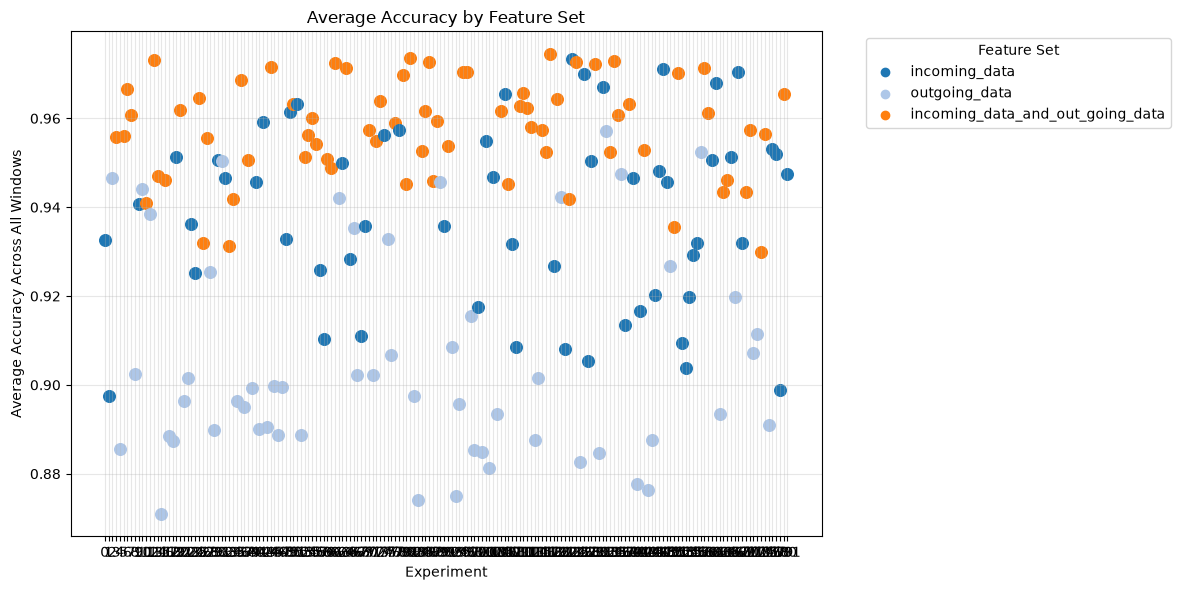

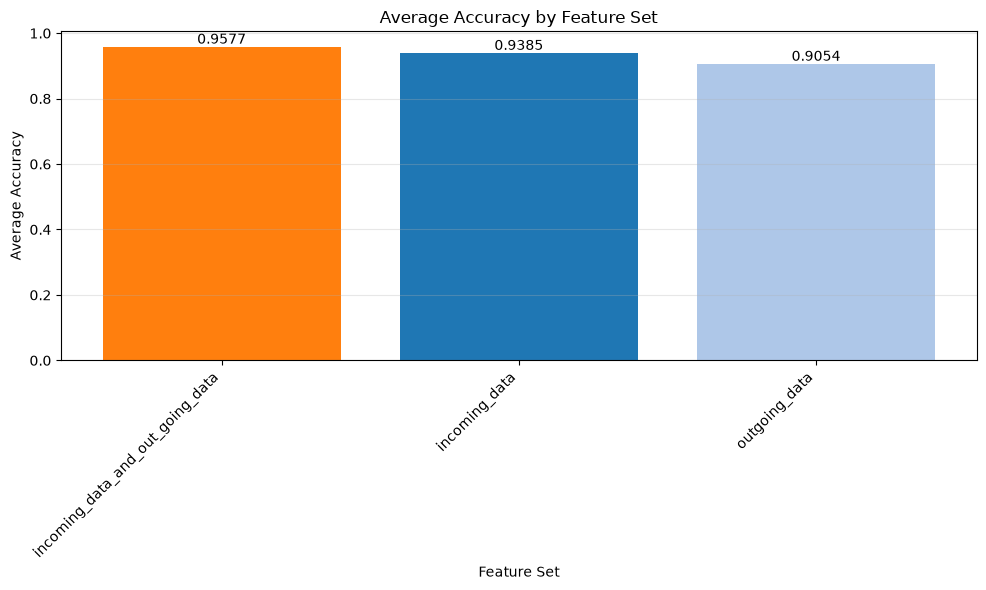

                        feature_set  accuracy
1  incoming_data_and_out_going_data  0.957682
0                     incoming_data  0.938548
2                     outgoing_data  0.905363


In [35]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
feature_sets = []
accuracies = []

for result in all_perfs.values():
    # if result["labeling_strategy"] == "nonIot-vs-iot":
    feature_sets.append(result["feature_set"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature set
# --------------------------------
unique_feature_sets = list(dict.fromkeys(feature_sets))

color_map = {
    feature_set: plt.cm.tab20(i % 20)
    for i, feature_set in enumerate(unique_feature_sets)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (feature_set, accuracy) in enumerate(
    zip(feature_sets, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[feature_set],
        s=70
    )

# Legend
for feature_set in unique_feature_sets:
    plt.scatter(
        [],
        [],
        color=color_map[feature_set],
        label=feature_set
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Feature Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Feature Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per feature set
# ==========================================

plot_df = pd.DataFrame({
    "feature_set": feature_sets,
    "accuracy": accuracies
})

avg_by_feature_set = (
    plot_df
    .groupby("feature_set", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_feature_set["feature_set"],
    avg_by_feature_set["accuracy"],
    color=[
        color_map[feature_set]
        for feature_set in avg_by_feature_set["feature_set"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_feature_set["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Feature Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Feature Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_feature_set["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_feature_set)

In [28]:
# num_features = []
# accuracies = []

# for result in all_perfs.values():
#     num_features.append(len(result["feature_combination"]))
#     accuracies.append(result["average_across_all_windows"])

# unique_num_features = sorted(set(num_features))

# color_map = {
#     n: plt.cm.tab10(i % 10)
#     for i, n in enumerate(unique_num_features)
# }

# plt.figure(figsize=(12, 6))

# for i, (n, accuracy) in enumerate(zip(num_features, accuracies)):
#     plt.scatter(
#         i,
#         accuracy,
#         color=color_map[n],
#         s=70
#     )

# for n in unique_num_features:
#     plt.scatter(
#         [],
#         [],
#         color=color_map[n],
#         label=f"{n} features"
#     )

# plt.xlabel("Experiment")
# plt.ylabel("Average Accuracy Across All Windows")
# plt.title("Average Accuracy by Number of Features")

# plt.xticks(range(len(accuracies)))
# plt.grid(alpha=0.3)

# plt.legend(
#     title="Number of Features",
#     bbox_to_anchor=(1.05, 1),
#     loc="upper left"
# )

# plt.tight_layout()
# plt.show()

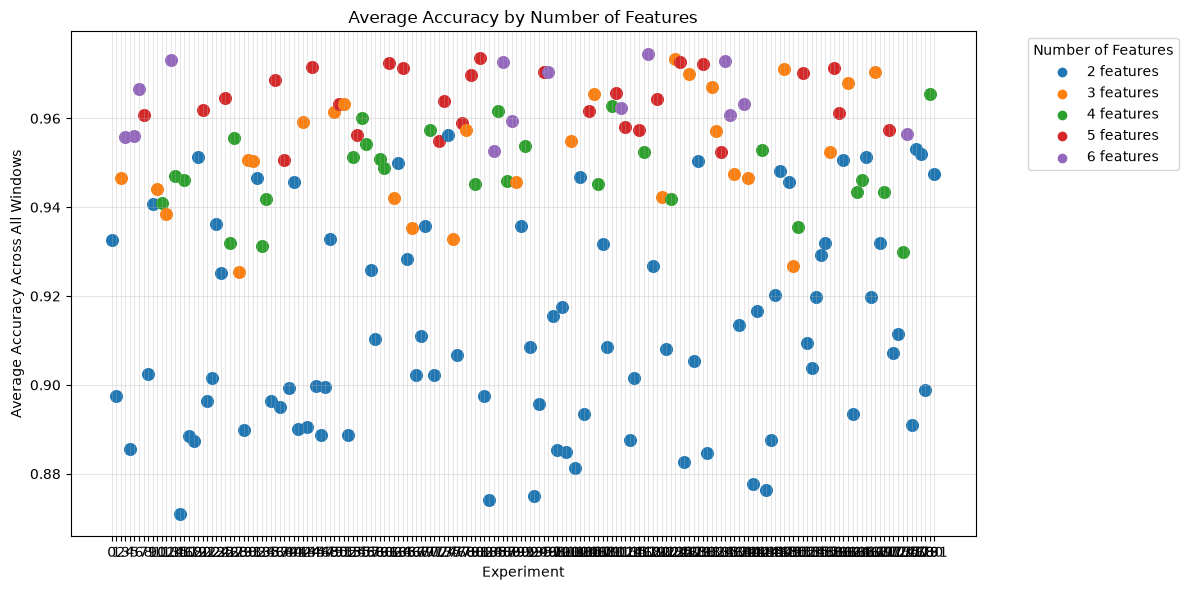

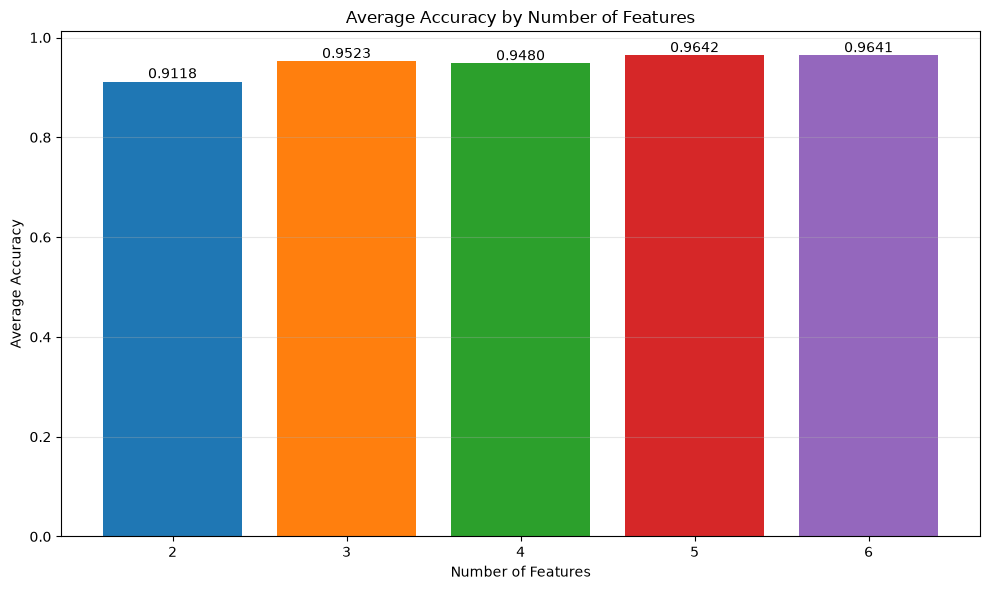

   num_features  accuracy
0             2  0.911824
1             3  0.952350
2             4  0.947961
3             5  0.964210
4             6  0.964068


In [39]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

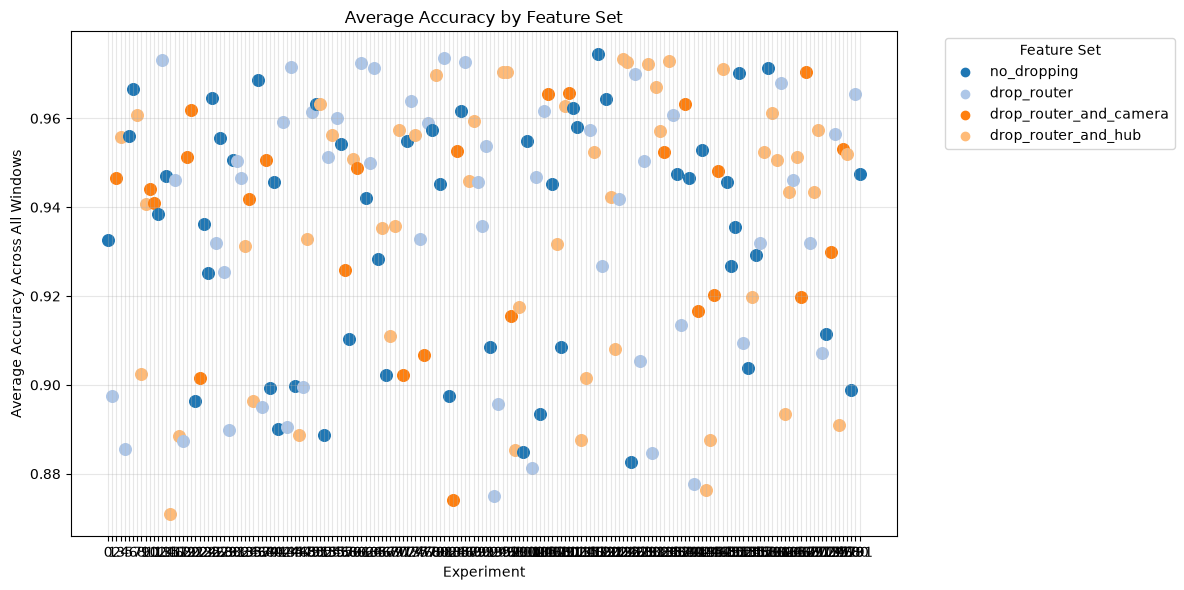

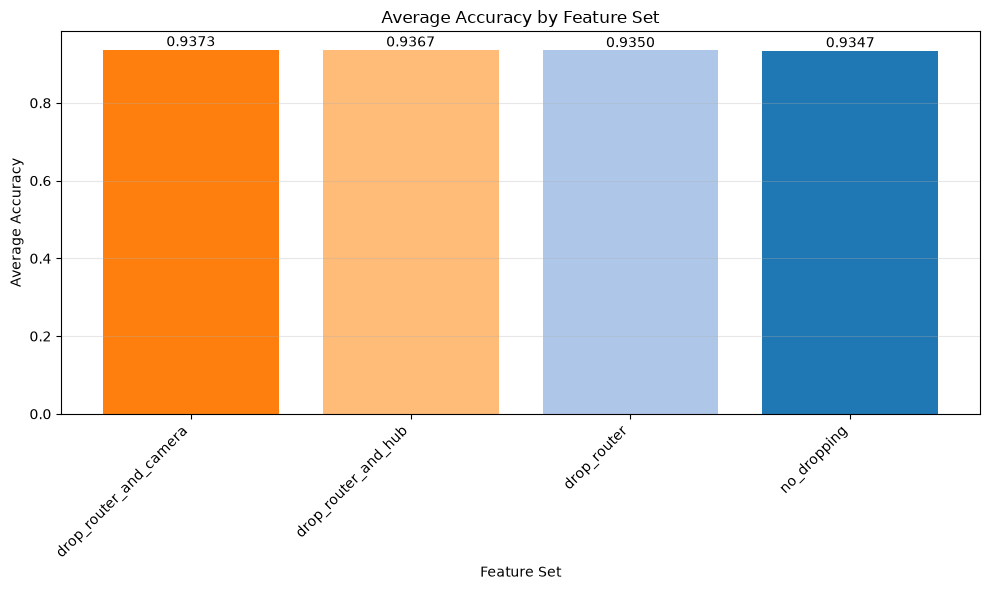

        dropping_strategy  accuracy
1  drop_router_and_camera  0.937287
2     drop_router_and_hub  0.936658
0             drop_router  0.934960
3             no_dropping  0.934676


In [32]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Feature Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Feature Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per feature set
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Feature Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Feature Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

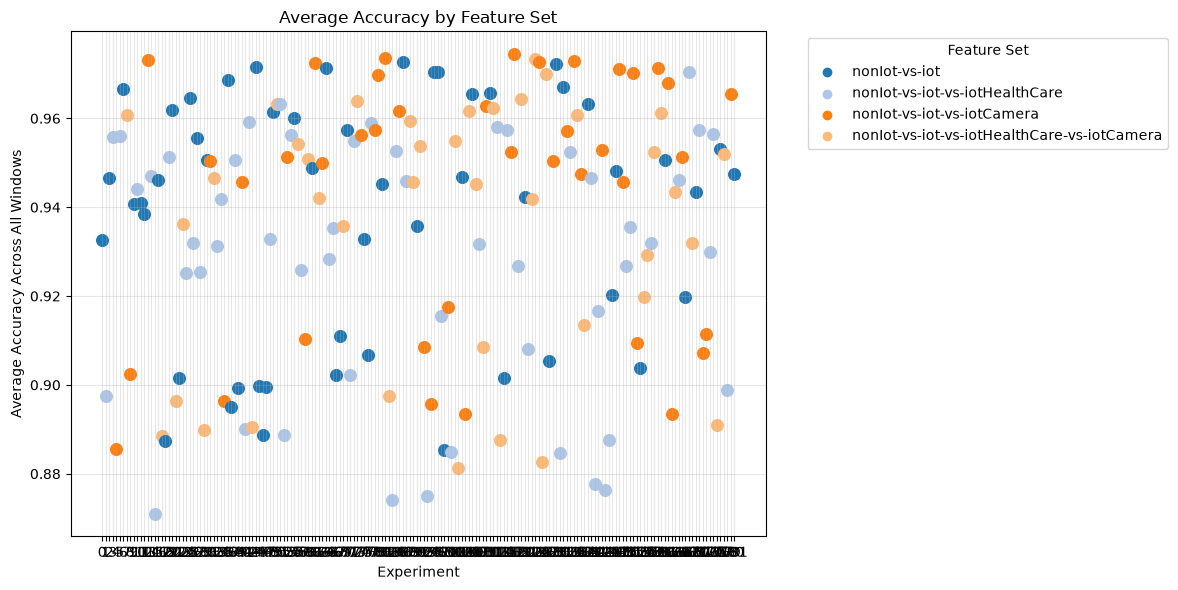

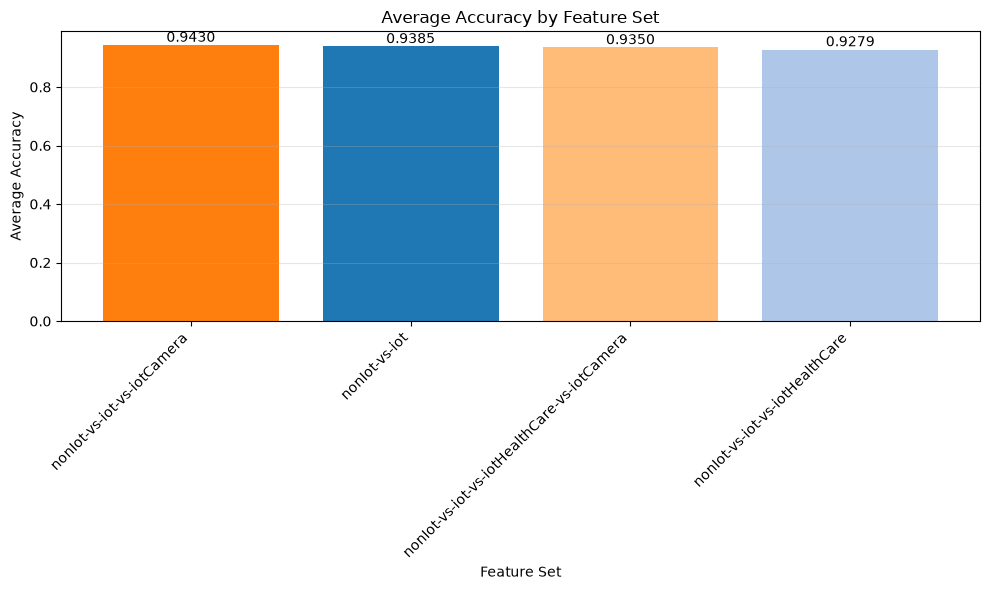

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.943045
0                                nonIot-vs-iot  0.938535
3  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.934966
2               nonIot-vs-iot-vs-iotHealthCare  0.927895


In [33]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Feature Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Feature Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per feature set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Feature Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Feature Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

# Comment on all hyperparameters
- With regard to different dropping_strategy and labeling_strategy, I don't see much improvement.
- The features set say otherwise.
    - The set of incoming features demonstrate better prediction compare to outgoing features. 
        - <mark>Explore why?</mark>
    - Both set together behave better compare to incoming features. The accuracy increase a bit, but the variance decrease -> stable prediction.
        - <mark>Explore why?</mark>
    

# Explore why we can't get to 100% even with all features together
- Let's figure out what is wrong with this

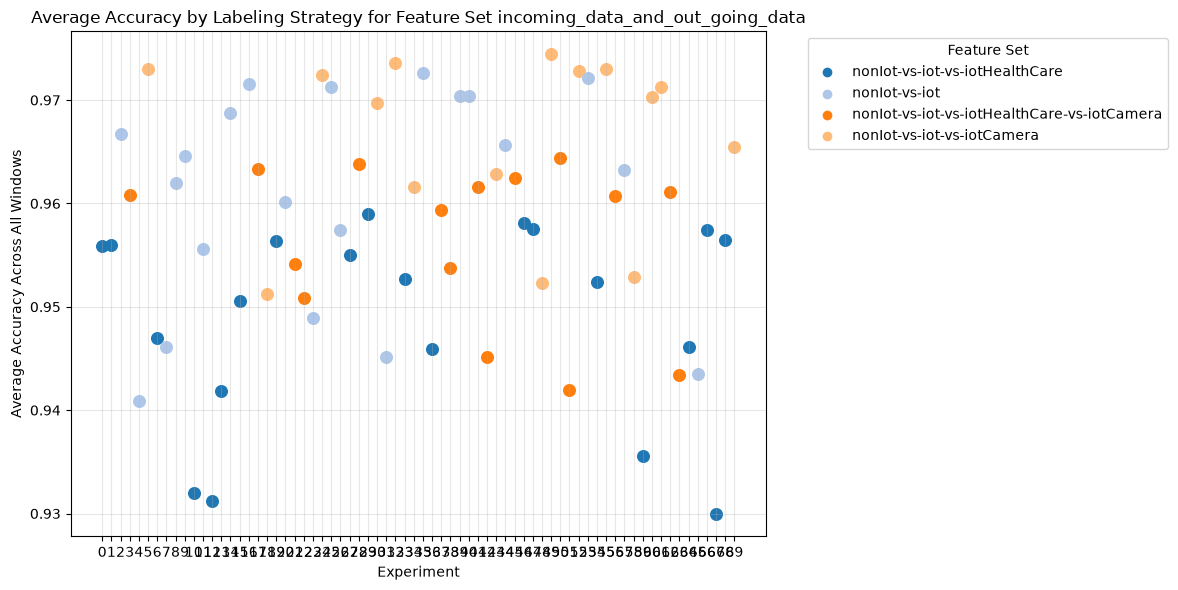

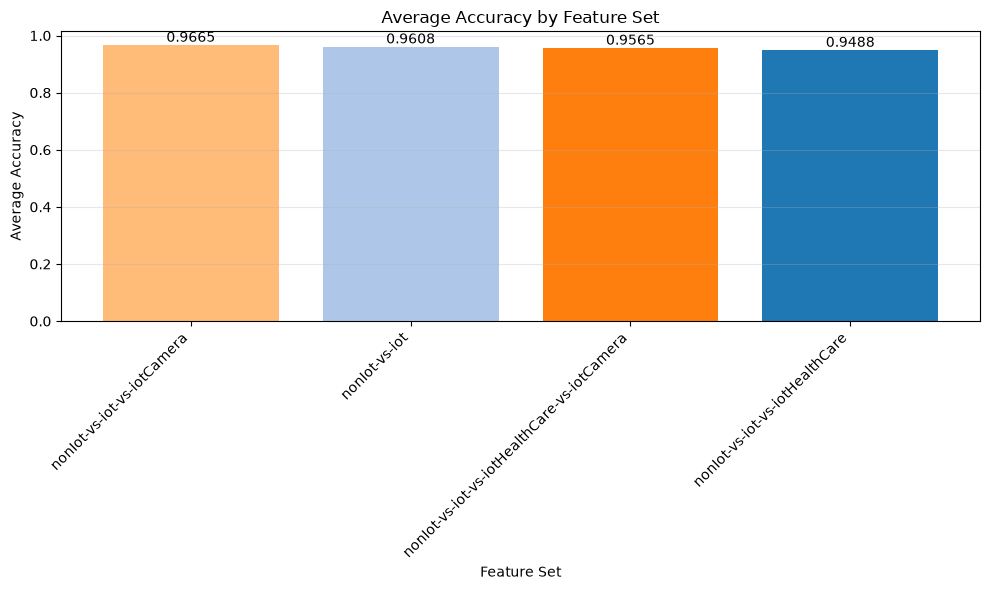

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.966467
0                                nonIot-vs-iot  0.960850
3  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.956458
2               nonIot-vs-iot-vs-iotHealthCare  0.948843


In [45]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if result["feature_set"] == "incoming_data_and_out_going_data":
        labeling_strategies.append(result["labeling_strategy"])
        accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Labeling Strategy for Feature Set incoming_data_and_out_going_data")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Feature Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per feature set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Feature Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Feature Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

- So nonIot-vs-iot-vs-iotCamera and nonIot-vs-iot are two labeling strategies that have higher accuracies


Labeling strategy: nonIot-vs-iot-vs-iotHealthCare
Total misclassified records: 6501


,mac,device_type,vendor,true_label,aggregated_prediction,fold,window,dropping_strategy,feature_combination,config_name
0,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,0,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
1,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,1,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
2,d0:a6:37:df:a1:e1,NaN,NaN,1,2,1,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,2,2,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
4,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,3,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
...,...,...,...,...,...,...,...,...,...,...
6496,18:b4:30:25:be:e4,smoke alarm,Nest,3,1,2,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
6497,d0:a6:37:df:a1:e1,NaN,NaN,1,2,3,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
6498,18:b4:30:25:be:e4,smoke alarm,Nest,3,1,4,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
6499,b4:ce:f6:a7:a3:c2,NaN,NaN,1,2,4,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...



Labeling strategy: nonIot-vs-iot
Total misclassified records: 4968


,mac,device_type,vendor,true_label,aggregated_prediction,fold,window,dropping_strategy,feature_combination,config_name
0,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,1,0,0,2,no_dropping,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
1,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,1,0,1,2,no_dropping,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
2,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,1,0,2,2,no_dropping,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,1,0,3,2,no_dropping,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
4,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,1,0,4,2,no_dropping,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
...,...,...,...,...,...,...,...,...,...,...
4963,b4:ce:f6:a7:a3:c2,NaN,NaN,0,1,4,10752,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...
4964,d0:a6:37:df:a1:e1,NaN,NaN,0,1,0,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...
4965,b4:ce:f6:a7:a3:c2,NaN,NaN,0,1,1,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...
4966,d0:a6:37:df:a1:e1,NaN,NaN,0,1,3,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...



Labeling strategy: nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera
Total misclassified records: 4349


,mac,device_type,vendor,true_label,aggregated_prediction,fold,window,dropping_strategy,feature_combination,config_name
0,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,0,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
1,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,1,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
2,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,2,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,3,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
4,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,3,1,4,2,drop_router_and_hub,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
...,...,...,...,...,...,...,...,...,...,...
4344,74:c6:3b:29:d7:1d,smart plug,iHome,2,1,3,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...
4345,ac:bc:32:d4:6f:2f,NaN,NaN,1,2,3,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...
4346,d0:a6:37:df:a1:e1,NaN,NaN,1,2,3,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...
4347,18:b4:30:25:be:e4,smoke alarm,Nest,3,1,4,11008,drop_router_and_hub,"[outgoing_packet_count, outgoing_total_bytes, ...",outgoing_packet_count_outgoing_total_bytes_out...



Labeling strategy: nonIot-vs-iot-vs-iotCamera
Total misclassified records: 3353


,mac,device_type,vendor,true_label,aggregated_prediction,fold,window,dropping_strategy,feature_combination,config_name
0,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,2,1,1,2,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
1,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,2,1,1,4,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
2,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,2,3,2,4,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,2,1,3,4,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
4,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,2,1,2,16,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
...,...,...,...,...,...,...,...,...,...,...
3348,d0:a6:37:df:a1:e1,NaN,NaN,1,2,0,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3349,18:b4:30:25:be:e4,smoke alarm,Nest,2,1,2,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3350,18:b4:30:25:be:e4,smoke alarm,Nest,2,1,4,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...
3351,b4:ce:f6:a7:a3:c2,NaN,NaN,1,2,4,11008,drop_router,"[incoming_packet_count, incoming_total_bytes, ...",incoming_packet_count_incoming_total_bytes_inc...


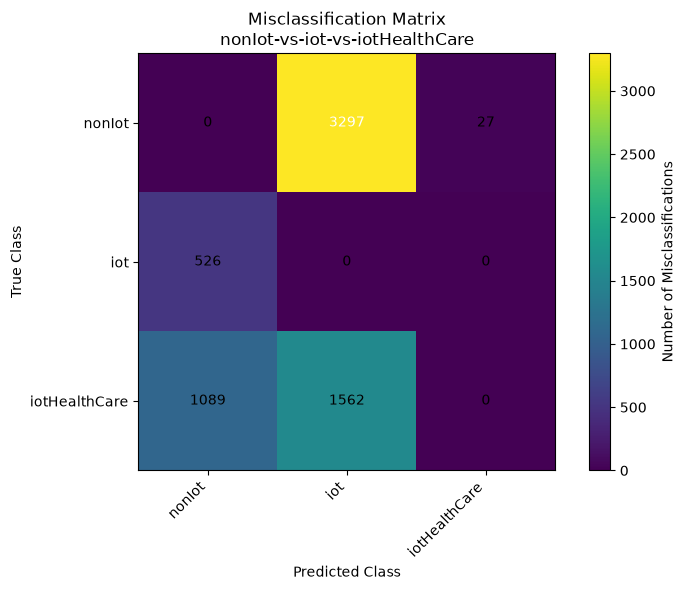

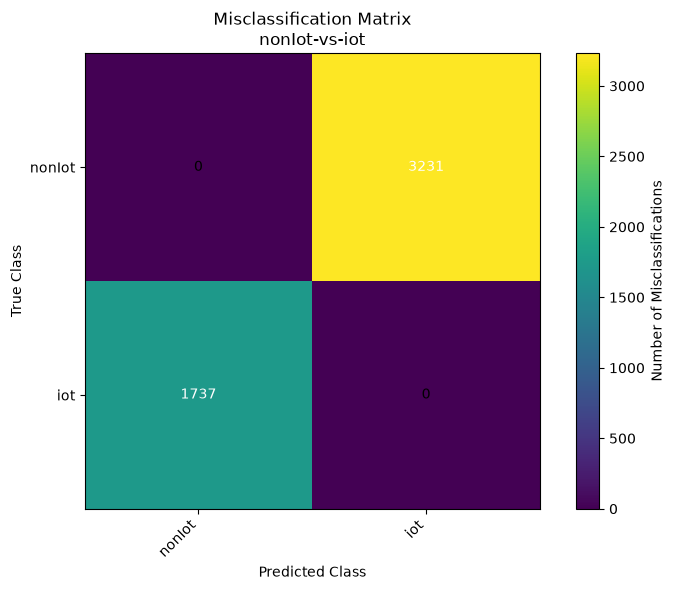

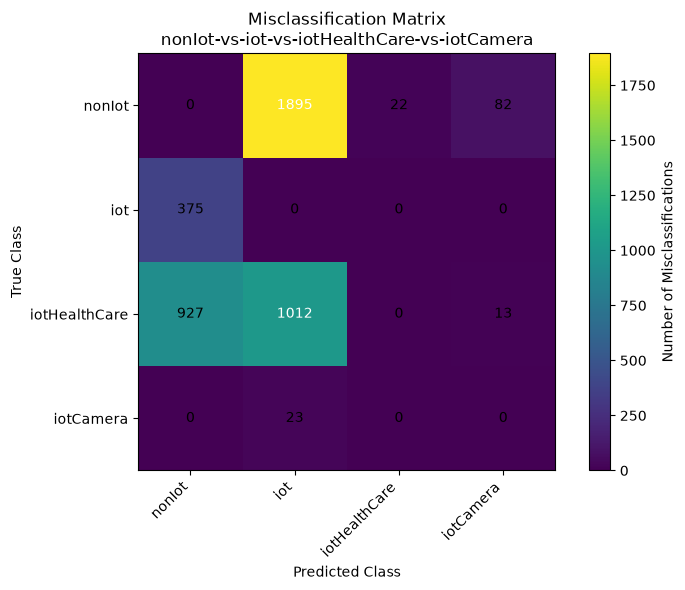

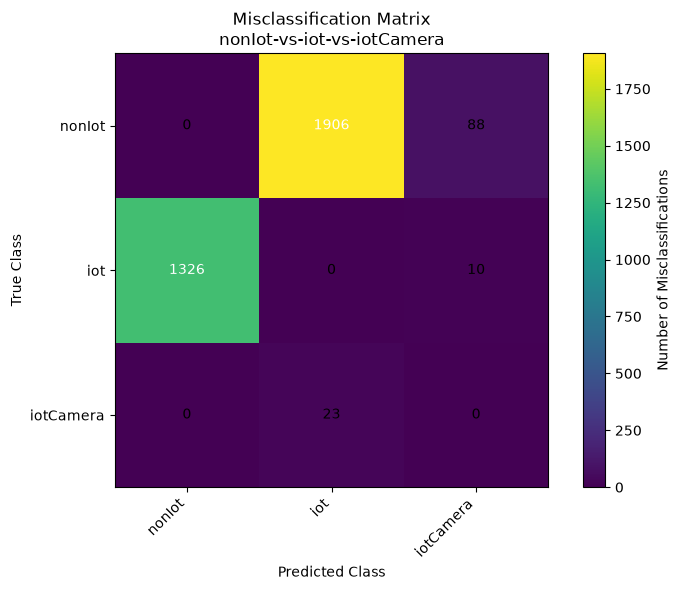


Misclassification summary: nonIot-vs-iot-vs-iotHealthCare


,true_label,true_class,aggregated_prediction,predicted_class,count
0,1,nonIot,2,iot,3297
4,3,iotHealthCare,2,iot,1562
3,3,iotHealthCare,1,nonIot,1089
2,2,iot,1,nonIot,526
1,1,nonIot,3,iotHealthCare,27



Misclassification summary: nonIot-vs-iot


,true_label,true_class,aggregated_prediction,predicted_class,count
0,0,nonIot,1,iot,3231
1,1,iot,0,nonIot,1737



Misclassification summary: nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera


,true_label,true_class,aggregated_prediction,predicted_class,count
0,1,nonIot,2,iot,1895
5,3,iotHealthCare,2,iot,1012
4,3,iotHealthCare,1,nonIot,927
3,2,iot,1,nonIot,375
2,1,nonIot,4,iotCamera,82
7,4,iotCamera,2,iot,23
1,1,nonIot,3,iotHealthCare,22
6,3,iotHealthCare,4,iotCamera,13



Misclassification summary: nonIot-vs-iot-vs-iotCamera


,true_label,true_class,aggregated_prediction,predicted_class,count
0,1,nonIot,2,iot,1906
2,2,iot,1,nonIot,1326
1,1,nonIot,3,iotCamera,88
4,3,iotCamera,2,iot,23
3,2,iot,3,iotCamera,10


In [42]:
TARGET_FEATURE_SET = "incoming_data_and_out_going_data"


# ============================================================
# 1. Gather all misclassified records by labeling strategy
# ============================================================

misclassified_by_strategy = {}

for config_name, result in all_perfs.items():

    # Only look at configs using both incoming + outgoing data
    if result["feature_set"] != TARGET_FEATURE_SET:
        continue

    labeling_strategy = result["labeling_strategy"]
    class_labels = result["class_labels"]

    detail_df = result["detail_performance"]

    # Misclassified records only
    misclassified = detail_df[
        detail_df["aggregated_prediction"] != detail_df["true_label"]
    ].copy()

    if misclassified.empty:
        continue

    # Add config-level information
    misclassified["config_name"] = config_name
    misclassified["feature_combination"] = [
        result["feature_combination"]
    ] * len(misclassified)

    misclassified["dropping_strategy"] = result["dropping_strategy"]
    misclassified["labeling_strategy"] = labeling_strategy

    # Add to appropriate labeling strategy
    if labeling_strategy not in misclassified_by_strategy:
        misclassified_by_strategy[labeling_strategy] = []

    misclassified_by_strategy[labeling_strategy].append(
        misclassified
    )


# Combine DataFrames inside each labeling strategy
for labeling_strategy in misclassified_by_strategy:

    misclassified_by_strategy[labeling_strategy] = pd.concat(
        misclassified_by_strategy[labeling_strategy],
        ignore_index=True
    )


# ============================================================
# 2. Show all misclassified records
# ============================================================

for labeling_strategy, df in misclassified_by_strategy.items():

    print("\n" + "=" * 100)
    print(f"Labeling strategy: {labeling_strategy}")
    print(f"Total misclassified records: {len(df)}")
    print("=" * 100)

    columns_to_show = [
        "mac",
        "device_type",
        "vendor",
        "true_label",
        "aggregated_prediction",
        "fold",
        "window",
        "dropping_strategy",
        "feature_combination",
        "config_name"
    ]

    columns_to_show = [
        col for col in columns_to_show
        if col in df.columns
    ]

    display(df[columns_to_show])


# ============================================================
# 3. Create label-name mapping
#
# Example:
# "nonIot-vs-iot-vs-iotCamera"
# class_labels = [1, 2, 3]
#
# becomes:
# 1 -> nonIot
# 2 -> iot
# 3 -> iotCamera
# ============================================================

def get_label_mapping(labeling_strategy, class_labels):

    class_names = labeling_strategy.split("-vs-")

    if len(class_names) != len(class_labels):
        # Fall back to numeric labels if naming does not match
        return {
            label: str(label)
            for label in class_labels
        }

    return dict(zip(class_labels, class_names))


# ============================================================
# 4. Plot misclassification matrix for each labeling strategy
# ============================================================

for labeling_strategy, df in misclassified_by_strategy.items():

    # Get class labels from actual data
    labels = sorted(
        set(df["true_label"]) |
        set(df["aggregated_prediction"])
    )

    label_mapping = get_label_mapping(
        labeling_strategy,
        labels
    )

    # Count true -> predicted errors
    matrix = pd.crosstab(
        df["true_label"],
        df["aggregated_prediction"]
    )

    # Make sure every class exists as both row and column
    matrix = matrix.reindex(
        index=labels,
        columns=labels,
        fill_value=0
    )

    # Rename labels to their semantic names
    matrix.index = [
        label_mapping[label]
        for label in matrix.index
    ]

    matrix.columns = [
        label_mapping[label]
        for label in matrix.columns
    ]

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    image = ax.imshow(matrix.values)

    ax.set_xticks(np.arange(len(matrix.columns)))
    ax.set_yticks(np.arange(len(matrix.index)))

    ax.set_xticklabels(
        matrix.columns,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(matrix.index)

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

    ax.set_title(
        f"Misclassification Matrix\n{labeling_strategy}"
    )

    # Add number to every cell
    max_value = matrix.values.max()

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):

            value = matrix.iloc[i, j]

            ax.text(
                j,
                i,
                str(value),
                ha="center",
                va="center",
                color=(
                    "white"
                    if max_value > 0 and value > max_value / 2
                    else "black"
                )
            )

    fig.colorbar(
        image,
        ax=ax,
        label="Number of Misclassifications"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. Produce summary tables: exactly what was confused with what
# ============================================================

misclassification_summary = {}

for labeling_strategy, df in misclassified_by_strategy.items():

    labels = sorted(
        set(df["true_label"]) |
        set(df["aggregated_prediction"])
    )

    label_mapping = get_label_mapping(
        labeling_strategy,
        labels
    )

    summary = (
        df.groupby(
            ["true_label", "aggregated_prediction"]
        )
        .size()
        .reset_index(name="count")
        .sort_values(
            "count",
            ascending=False
        )
    )

    summary["true_class"] = (
        summary["true_label"]
        .map(label_mapping)
    )

    summary["predicted_class"] = (
        summary["aggregated_prediction"]
        .map(label_mapping)
    )

    summary = summary[
        [
            "true_label",
            "true_class",
            "aggregated_prediction",
            "predicted_class",
            "count"
        ]
    ]

    misclassification_summary[
        labeling_strategy
    ] = summary

    print("\n" + "=" * 100)
    print(
        f"Misclassification summary: "
        f"{labeling_strategy}"
    )
    print("=" * 100)

    display(summary)


Labeling strategy: nonIot-vs-iot-vs-iotHealthCare


,mac,device_type,vendor,true_class,predicted_class,misclassification_count,total_misclassifications
4,18:b4:30:25:be:e4,smoke alarm,Nest,iotHealthCare,iot,1192,1904
3,18:b4:30:25:be:e4,smoke alarm,Nest,iotHealthCare,nonIot,712,1904
14,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iot,1295,1322
15,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iotHealthCare,27,1322
5,40:f3:08:ff:1e:da,NaN,NaN,nonIot,iot,700,700
13,b4:ce:f6:a7:a3:c2,NaN,NaN,nonIot,iot,622,622
9,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iotHealthCare,nonIot,299,559
10,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iotHealthCare,iot,260,559
11,74:c6:3b:29:d7:1d,smart plug,iHome,iot,nonIot,520,520
2,08:21:ef:3b:fc:e3,NaN,NaN,nonIot,iot,358,358



Labeling strategy: nonIot-vs-iot


,mac,device_type,vendor,true_class,predicted_class,misclassification_count,total_misclassifications
9,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iot,1294,1294
5,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iot,nonIot,961,961
3,40:f3:08:ff:1e:da,NaN,NaN,nonIot,iot,691,691
8,b4:ce:f6:a7:a3:c2,NaN,NaN,nonIot,iot,592,592
6,74:c6:3b:29:d7:1d,smart plug,iHome,iot,nonIot,371,371
2,18:b4:30:25:be:e4,smoke alarm,Nest,iot,nonIot,340,340
1,08:21:ef:3b:fc:e3,NaN,NaN,nonIot,iot,331,331
7,ac:bc:32:d4:6f:2f,NaN,NaN,nonIot,iot,234,234
4,74:2f:68:81:69:42,NaN,NaN,nonIot,iot,89,89
0,00:24:e4:1b:6f:96,smart scale,Withings,iot,nonIot,65,65



Labeling strategy: nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera


,mac,device_type,vendor,true_class,predicted_class,misclassification_count,total_misclassifications
5,18:b4:30:25:be:e4,smoke alarm,Nest,iotHealthCare,iot,784,1417
4,18:b4:30:25:be:e4,smoke alarm,Nest,iotHealthCare,nonIot,628,1417
6,18:b4:30:25:be:e4,smoke alarm,Nest,iotHealthCare,iotCamera,5,1417
19,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iot,942,963
20,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iotHealthCare,20,963
21,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iotCamera,1,963
10,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iotHealthCare,nonIot,237,417
11,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iotHealthCare,iot,176,417
12,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iotHealthCare,iotCamera,4,417
16,b4:ce:f6:a7:a3:c2,NaN,NaN,nonIot,iot,373,381



Labeling strategy: nonIot-vs-iot-vs-iotCamera


,mac,device_type,vendor,true_class,predicted_class,misclassification_count,total_misclassifications
16,d0:a6:37:df:a1:e1,NaN,NaN,nonIot,iot,981,981
8,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iot,nonIot,725,730
9,74:6a:89:00:2e:25,blood pressure monitor,Blipcare,iot,iotCamera,5,730
14,b4:ce:f6:a7:a3:c2,NaN,NaN,nonIot,iot,343,349
15,b4:ce:f6:a7:a3:c2,NaN,NaN,nonIot,iotCamera,6,349
3,18:b4:30:25:be:e4,smoke alarm,Nest,iot,nonIot,280,283
4,18:b4:30:25:be:e4,smoke alarm,Nest,iot,iotCamera,3,283
5,40:f3:08:ff:1e:da,NaN,NaN,nonIot,iot,278,278
10,74:c6:3b:29:d7:1d,smart plug,iHome,iot,nonIot,263,264
11,74:c6:3b:29:d7:1d,smart plug,iHome,iot,iotCamera,1,264


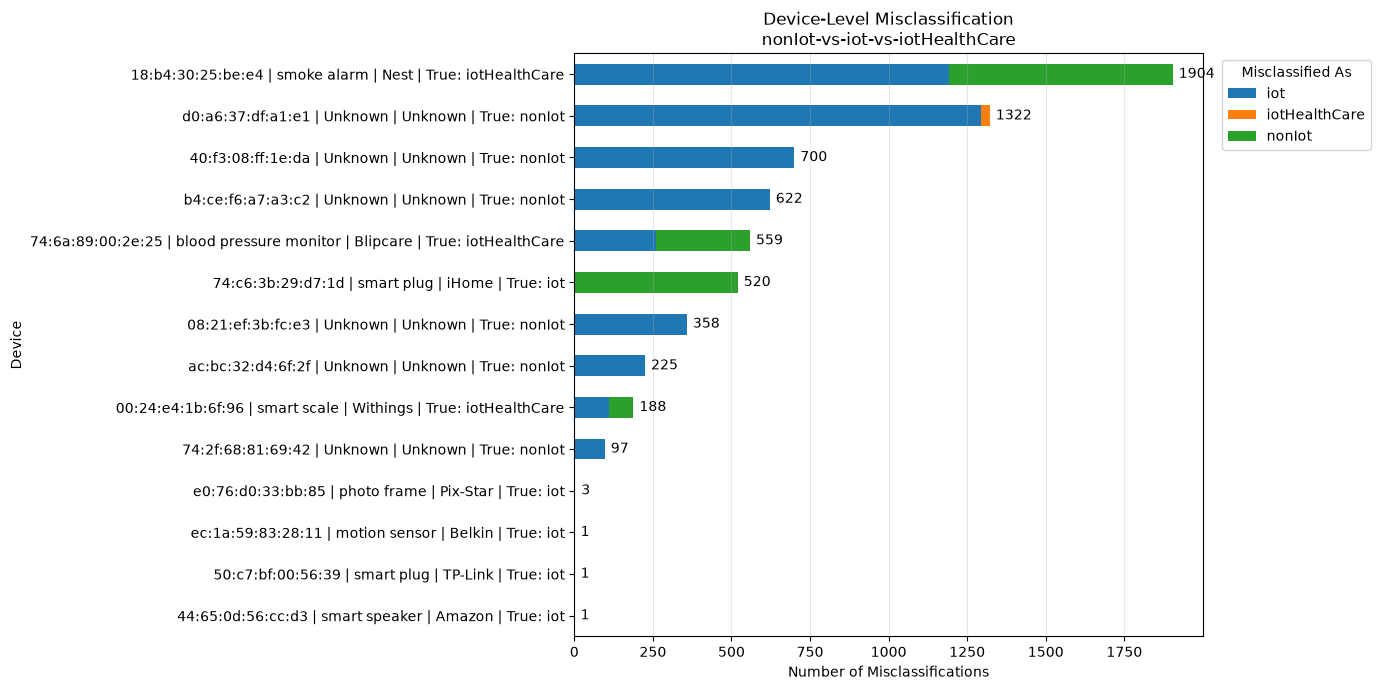

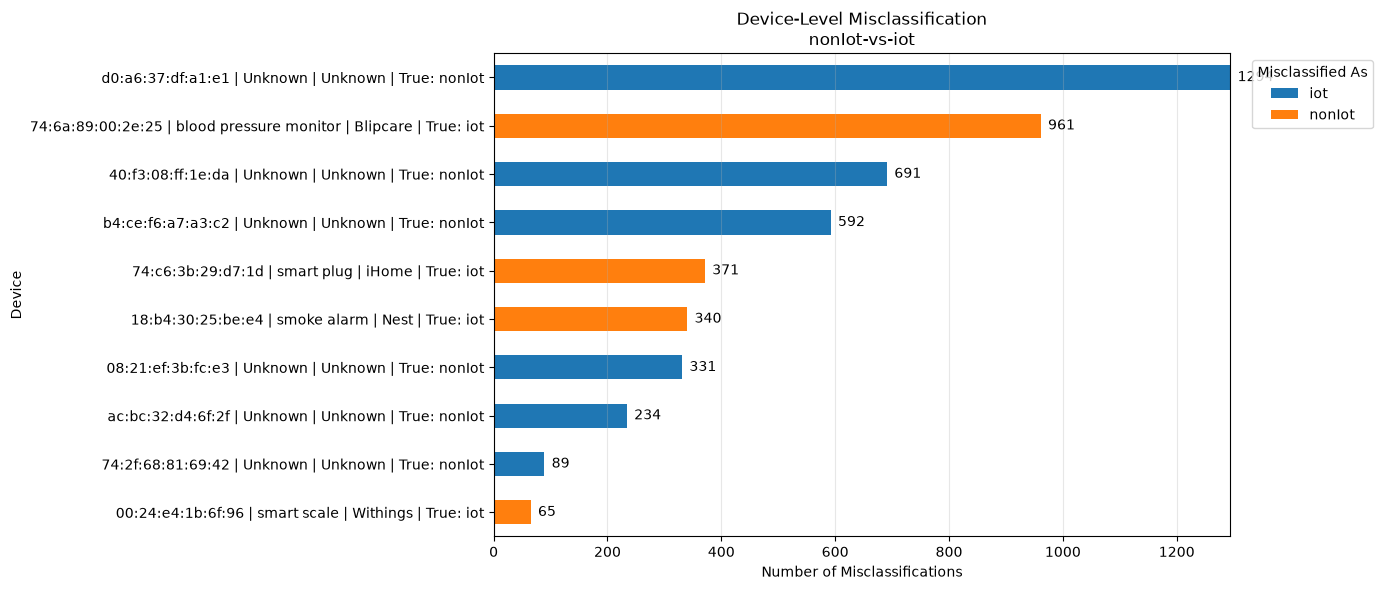

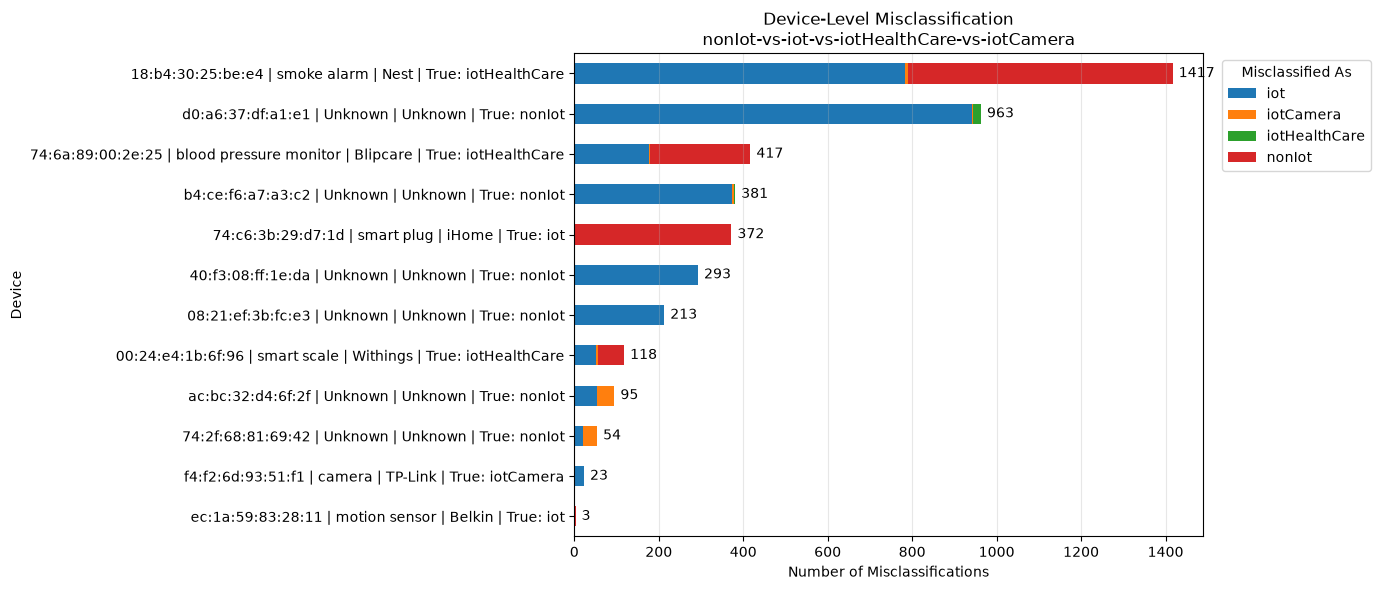

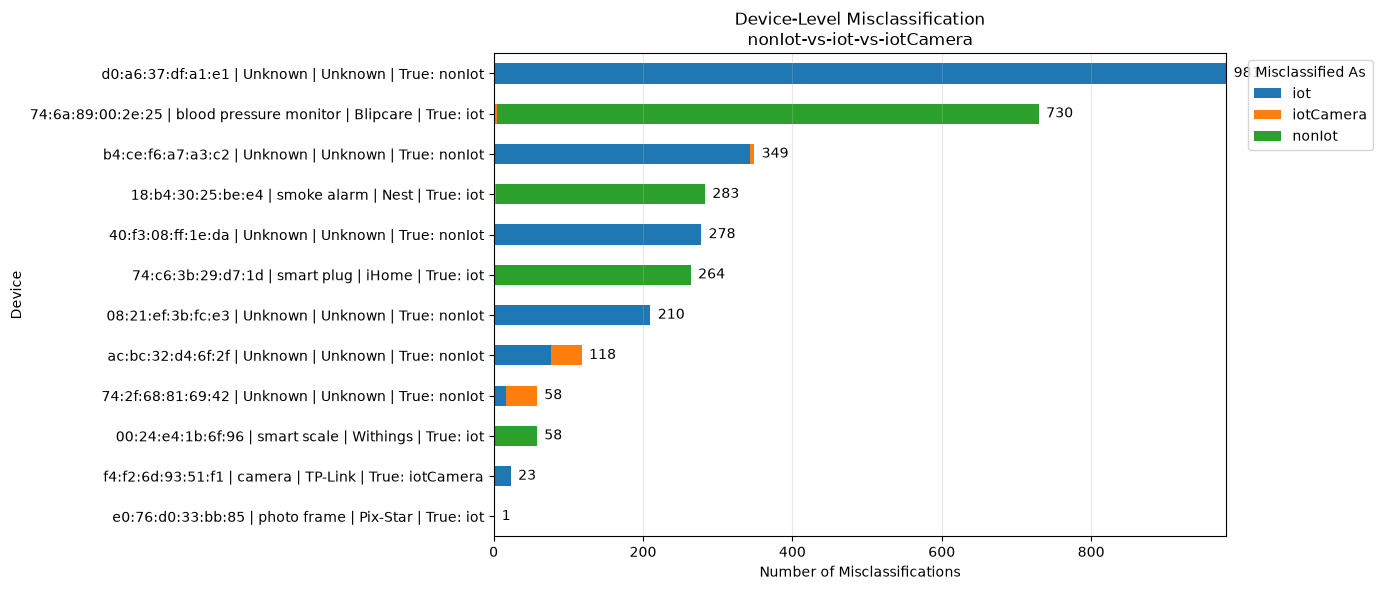

In [44]:
TARGET_FEATURE_SET = "incoming_data_and_out_going_data"

misclassified_by_strategy = {}
class_labels_by_strategy = {}


# ============================================================
# 1. Collect misclassified records
# ============================================================

for config_name, result in all_perfs.items():

    if result["feature_set"] != TARGET_FEATURE_SET:
        continue

    labeling_strategy = result["labeling_strategy"]
    class_labels = result["class_labels"]

    class_labels_by_strategy[labeling_strategy] = class_labels

    detail_df = result["detail_performance"]

    misclassified = detail_df[
        detail_df["aggregated_prediction"] != detail_df["true_label"]
    ].copy()

    if misclassified.empty:
        continue

    # Add useful config information
    misclassified["config_name"] = config_name
    misclassified["dropping_strategy"] = result["dropping_strategy"]
    misclassified["feature_combination"] = [
        result["feature_combination"]
    ] * len(misclassified)

    misclassified["labeling_strategy"] = labeling_strategy

    if labeling_strategy not in misclassified_by_strategy:
        misclassified_by_strategy[labeling_strategy] = []

    misclassified_by_strategy[labeling_strategy].append(
        misclassified
    )


# Combine records for each labeling strategy
for strategy in misclassified_by_strategy:
    misclassified_by_strategy[strategy] = pd.concat(
        misclassified_by_strategy[strategy],
        ignore_index=True
    )


# ============================================================
# 2. Helper: class label -> readable class name
# ============================================================

def get_label_mapping(labeling_strategy, class_labels):

    class_names = labeling_strategy.split("-vs-")

    if len(class_names) != len(class_labels):
        return {
            label: str(label)
            for label in class_labels
        }

    return dict(zip(class_labels, class_names))


# ============================================================
# 3. Build device-level misclassification information
# ============================================================

device_error_summaries = {}

for labeling_strategy, df in misclassified_by_strategy.items():

    class_labels = class_labels_by_strategy[labeling_strategy]

    label_mapping = get_label_mapping(
        labeling_strategy,
        class_labels
    )

    # --------------------------------------------------------
    # Count:
    #
    # Device X
    # true class = 2
    # predicted as 1 -> 10 times
    # predicted as 3 -> 4 times
    # --------------------------------------------------------

    device_summary = (
        df.groupby(
            [
                "mac",
                "device_type",
                "vendor",
                "true_label",
                "aggregated_prediction"
            ],
            dropna=False
        )
        .size()
        .reset_index(name="misclassification_count")
    )

    device_summary["true_class"] = (
        device_summary["true_label"]
        .map(label_mapping)
    )

    device_summary["predicted_class"] = (
        device_summary["aggregated_prediction"]
        .map(label_mapping)
    )

    # Total errors made for each device
    total_errors = (
        device_summary
        .groupby(
            ["mac", "device_type", "vendor"],
            dropna=False
        )["misclassification_count"]
        .sum()
        .reset_index(name="total_misclassifications")
    )

    device_summary = device_summary.merge(
        total_errors,
        on=["mac", "device_type", "vendor"],
        how="left"
    )

    device_summary = device_summary.sort_values(
        [
            "total_misclassifications",
            "mac",
            "misclassification_count"
        ],
        ascending=[False, True, False]
    )

    device_error_summaries[labeling_strategy] = device_summary


# ============================================================
# 4. Display device-level information
# ============================================================

for labeling_strategy, df in device_error_summaries.items():

    print("\n" + "=" * 120)
    print(f"Labeling strategy: {labeling_strategy}")
    print("=" * 120)

    display(
        df[
            [
                "mac",
                "device_type",
                "vendor",
                "true_class",
                "predicted_class",
                "misclassification_count",
                "total_misclassifications"
            ]
        ]
    )


# ============================================================
# 5. Plot one graph for each labeling strategy
# ============================================================

for labeling_strategy, df in device_error_summaries.items():

    df = df.copy()

    # --------------------------------------------------------
    # Create readable device identifier including true label
    # --------------------------------------------------------

    df["device"] = (
        df["mac"].astype(str)
        + " | "
        + df["device_type"].fillna("Unknown").astype(str)
        + " | "
        + df["vendor"].fillna("Unknown").astype(str)
        + " | True: "
        + df["true_class"].astype(str)
    )

    # --------------------------------------------------------
    # Rows = devices
    # Columns = classes they were misclassified as
    # Values = number of misclassifications
    # --------------------------------------------------------

    pivot = df.pivot_table(
        index="device",
        columns="predicted_class",
        values="misclassification_count",
        aggfunc="sum",
        fill_value=0
    )

    # Sort by total number of misclassifications
    pivot["total"] = pivot.sum(axis=1)

    pivot = pivot.sort_values(
        "total",
        ascending=True
    )

    total_errors = pivot.pop("total")

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    ax = pivot.plot(
        kind="barh",
        stacked=True,
        figsize=(14, max(6, len(pivot) * 0.5))
    )

    ax.set_xlabel("Number of Misclassifications")
    ax.set_ylabel("Device")

    ax.set_title(
        f"Device-Level Misclassification\n"
        f"{labeling_strategy}"
    )

    ax.legend(
        title="Misclassified As",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.grid(
        axis="x",
        alpha=0.3
    )

    # --------------------------------------------------------
    # Show total errors at the end of each bar
    # --------------------------------------------------------

    max_total = total_errors.max()

    for i, total in enumerate(total_errors):
        ax.text(
            total + max_total * 0.01,
            i,
            str(int(total)),
            va="center"
        )

    plt.tight_layout()
    plt.show()

- IPhone (d0:a6:37:df:a1:e1) is usually the one that get misclassified a lot. 

- Mixing good config together
- Add all_data together
- Consider idle time to be last active (both outgoing and incoming)
- Analyze the extreme worst point of data